# Computational Lab 5 — Effective mass: from band curvature to transport

The effective-mass model is the interface between a crystal's band structure
and the Maxwell–Boltzmann/Langevin/Drude model. This lab extracts an effective-
mass tensor from a model conduction band and follows that tensor into carrier
statistics, thermal velocities, diffusion, mobility, and conductivity.

**Learning goals**

1. calculate $\mathbf M^*$ from the Hessian of $E(\mathbf k)$;
2. understand the local parabolic approximation and its limits;
3. distinguish density-of-states and conductivity masses; and
4. use the mass tensor in Maxwell–Boltzmann and Drude transport.

We use silicon-like longitudinal and transverse masses as an instructive
multivalley example. The cosine band is a pedagogical periodic band, not a
full empirical silicon band structure.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "lecture-notes" / "main.tex").exists()
)
OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 1. Band curvature defines the effective-mass tensor

Near a conduction-band minimum $\mathbf k_0$, write
$\mathbf q=\mathbf k-\mathbf k_0$. The quadratic expansion is

\[
 E(\mathbf k)\approx E_c+
 \frac{\hbar^2}{2}\mathbf q^T\mathbf M^{*-1}\mathbf q,
 \qquad
 \left(\mathbf M^{*-1}\right)_{ij}
 =\frac{1}{\hbar^2}
 \frac{\partial^2E}{\partial k_i\partial k_j}\bigg|_{\mathbf k_0}.
\]

We construct a periodic separable band

\[
 E(\mathbf q)-E_c=\sum_i2t_i[1-\cos(q_i a)],
 \qquad t_i=\frac{\hbar^2}{2m_i^*a^2}.
\]

Its curvature at the minimum has the requested mass, while its departure from
a parabola away from the minimum makes the approximation's locality visible.

In [2]:
# SI constants and silicon-like parameters.
hbar = 1.054_571_817e-34              # J s
planck = 2.0 * np.pi * hbar
boltzmann = 1.380_649e-23             # J/K
elementary_charge = 1.602_176_634e-19 # C
electron_mass = 9.109_383_7139e-31    # kg
temperature = 300.0                    # K
lattice_scale = 0.543e-9               # m
transverse_mass = 0.190 * electron_mass
longitudinal_mass = 0.916 * electron_mass
principal_masses = np.array([
    transverse_mass,
    transverse_mass,
    longitudinal_mass,
])
hopping_energy = hbar**2 / (2.0 * principal_masses * lattice_scale**2)


def band_energy(wavevector):
    # Energy relative to the band minimum for a valley along z.
    wavevector = np.asarray(wavevector)
    return np.sum(
        2.0 * hopping_energy * (1.0 - np.cos(wavevector * lattice_scale)),
        axis=-1,
    )


reduced_wavevector = np.linspace(-1.5, 1.5, 500)  # q_i a
q_line = reduced_wavevector / lattice_scale
transverse_band = np.array([
    band_energy([value, 0.0, 0.0]) for value in q_line
]) / elementary_charge
longitudinal_band = np.array([
    band_energy([0.0, 0.0, value]) for value in q_line
]) / elementary_charge
transverse_parabola = hbar**2 * q_line**2 / (2.0 * transverse_mass * elementary_charge)
longitudinal_parabola = hbar**2 * q_line**2 / (2.0 * longitudinal_mass * elementary_charge)

## 2. Recover the tensor numerically

A centered finite-difference Hessian treats the band function as numerical
data. In a measured or calculated band, this is the step where the effective-
mass model is fitted. The result depends on the fitting window if the band is
not exactly parabolic.

In [3]:
def numerical_hessian(function, point, step):
    # Centered second derivatives, including mixed derivatives.
    point = np.asarray(point, dtype=float)
    dimension = point.size
    result = np.zeros((dimension, dimension))
    center_value = function(point)
    for i in range(dimension):
        direction_i = np.zeros(dimension)
        direction_i[i] = step
        result[i, i] = (
            function(point + direction_i)
            - 2.0 * center_value
            + function(point - direction_i)
        ) / step**2
        for j in range(i + 1, dimension):
            direction_j = np.zeros(dimension)
            direction_j[j] = step
            mixed = (
                function(point + direction_i + direction_j)
                - function(point + direction_i - direction_j)
                - function(point - direction_i + direction_j)
                + function(point - direction_i - direction_j)
            ) / (4.0 * step**2)
            result[i, j] = result[j, i] = mixed
    return result


curvature_step = 1.0e7  # m^-1, so step*a is much less than one
hessian = numerical_hessian(band_energy, np.zeros(3), curvature_step)
inverse_mass_tensor = hessian / hbar**2
recovered_mass_tensor = np.linalg.inv(inverse_mass_tensor)
recovered_principal_masses = np.linalg.eigvalsh(recovered_mass_tensor)

assert np.allclose(recovered_mass_tensor, np.diag(principal_masses), rtol=1.0e-5, atol=0.0)
print("recovered mass tensor / m0:")
print(recovered_mass_tensor / electron_mass)
print("principal masses / m0:", recovered_principal_masses / electron_mass)

recovered mass tensor / m0:
[[0.19000047 0.         0.        ]
 [0.         0.19000047 0.        ]
 [0.         0.         0.91600225]]
principal masses / m0: [0.19000047 0.19000047 0.91600225]


## 3. Maxwell–Boltzmann equilibrium becomes anisotropic

The band velocity follows from the band gradient,

\[
 \mathbf v=\frac{1}{\hbar}\nabla_{\mathbf k}E
 \approx\hbar\mathbf M^{*-1}\mathbf q.
\]

In a nondegenerate parabolic valley, the velocity distribution is

\[
 f(\mathbf v)\propto
 \exp\!\left[-\frac{\mathbf v^T\mathbf M^*\mathbf v}{2k_BT}\right],
 \qquad
 \langle\mathbf v\mathbf v^T\rangle=k_BT\mathbf M^{*-1}.
\]

A heavier longitudinal mass therefore gives a narrower longitudinal velocity
distribution. Equipartition remains $\tfrac12k_BT$ per quadratic direction.

In [4]:
rng = np.random.default_rng(62715)
sample_count = 120_000
thermal_standard_deviation = np.sqrt(
    boltzmann * temperature / principal_masses
)
velocity_samples = (
    rng.standard_normal((sample_count, 3)) * thermal_standard_deviation
)
sampled_covariance = np.cov(velocity_samples, rowvar=False, ddof=0)
expected_covariance = boltzmann * temperature * inverse_mass_tensor
sampled_kinetic_energy = 0.5 * np.mean(
    np.sum(principal_masses * velocity_samples**2, axis=1)
)

assert np.allclose(np.diag(sampled_covariance), np.diag(expected_covariance), rtol=0.015)
sampled_correlation = sampled_covariance / np.sqrt(np.outer(np.diag(sampled_covariance), np.diag(sampled_covariance)))
assert np.max(np.abs(sampled_correlation - np.eye(3))) < 0.01
assert np.isclose(sampled_kinetic_energy, 1.5 * boltzmann * temperature, rtol=0.01)
print("thermal velocity standard deviations (km/s):", thermal_standard_deviation / 1e3)
print("<K> / (3 kT/2):", sampled_kinetic_energy / (1.5 * boltzmann * temperature))

thermal velocity standard deviations (km/s): [154.69667176 154.69667176  70.45471034]
<K> / (3 kT/2): 0.9985078931045293


## 4. DOS mass and conductivity mass answer different questions

For one ellipsoidal valley with principal masses $m_t,m_t,m_l$, the
three-dimensional density-of-states mass is

\[
 m_{\mathrm{DOS},1}=(m_t^2m_l)^{1/3}.
\]

Six equivalent valleys multiply the available states. The single isotropic
mass that reproduces their total DOS is

\[
 m_{\mathrm{DOS,total}}=g_v^{2/3}m_{\mathrm{DOS},1}.
\]

Transport instead averages inverse masses. For six equally occupied valleys
oriented along the three crystal axes,

\[
 m_{\mathrm{cond}}=rac{3}{1/m_l+2/m_t}.
\]

The DOS mass determines how many carriers are populated; the conductivity mass
determines how strongly those carriers accelerate.

In [5]:
valley_degeneracy = 6
one_valley_dos_mass = (
    transverse_mass**2 * longitudinal_mass
) ** (1.0 / 3.0)
total_dos_mass = valley_degeneracy ** (2.0 / 3.0) * one_valley_dos_mass
conductivity_mass = 3.0 / (
    1.0 / longitudinal_mass + 2.0 / transverse_mass
)

# Two valleys are longitudinal along each Cartesian axis.
valley_mass_tensors = [
    np.diag([longitudinal_mass, transverse_mass, transverse_mass]),
    np.diag([longitudinal_mass, transverse_mass, transverse_mass]),
    np.diag([transverse_mass, longitudinal_mass, transverse_mass]),
    np.diag([transverse_mass, longitudinal_mass, transverse_mass]),
    np.diag([transverse_mass, transverse_mass, longitudinal_mass]),
    np.diag([transverse_mass, transverse_mass, longitudinal_mass]),
]
average_inverse_mass = np.mean(
    [np.linalg.inv(tensor) for tensor in valley_mass_tensors], axis=0
)

assert np.allclose(
    average_inverse_mass,
    np.eye(3) / conductivity_mass,
    rtol=1.0e-14,
)
print(f"one-valley DOS mass / m0 = {one_valley_dos_mass / electron_mass:.4f}")
print(f"six-valley DOS mass / m0 = {total_dos_mass / electron_mass:.4f}")
print(f"conductivity mass / m0    = {conductivity_mass / electron_mass:.4f}")

one-valley DOS mass / m0 = 0.3210
six-valley DOS mass / m0 = 1.0598
conductivity mass / m0    = 0.2582


## 5. Carrier population and transport

In the Maxwell–Boltzmann limit, the effective conduction-band density of
states and electron density are

\[
 N_c=2g_v\left(\frac{2\pi m_{\mathrm{DOS},1}k_BT}{h^2}\right)^{3/2},
 \qquad
 n=N_c\exp\!\left[-\frac{E_c-E_F}{k_BT}\right].
\]

For momentum-relaxation time $\tau$, a single valley has tensor relations

\[
 \mathbf D=k_BT\tau\mathbf M^{*-1},\qquad
 \boldsymbol\mu=|q|\tau\mathbf M^{*-1},\qquad
 \boldsymbol\sigma=nq^2\tau\mathbf M^{*-1}.
\]

These obey the tensor Einstein relation
$\mathbf D=(k_BT/|q|)\boldsymbol\mu$. Averaging the inverse mass over all six
valleys makes the transport isotropic in this idealized example.

In [6]:
relaxation_time = 0.20e-12       # s
fermi_level_below_edge_ev = 0.20 # eV
fermi_offset = fermi_level_below_edge_ev * elementary_charge

effective_density_of_states = 2.0 * valley_degeneracy * (
    2.0 * np.pi * one_valley_dos_mass * boltzmann * temperature / planck**2
) ** 1.5
electron_density = effective_density_of_states * np.exp(
    -fermi_offset / (boltzmann * temperature)
)
one_valley_diffusivity = (
    boltzmann * temperature * relaxation_time * inverse_mass_tensor
)
one_valley_mobility = (
    elementary_charge * relaxation_time * inverse_mass_tensor
)
combined_mobility = (
    elementary_charge * relaxation_time * average_inverse_mass
)
combined_conductivity = (
    electron_density * elementary_charge**2 * relaxation_time
    * average_inverse_mass
)

assert np.allclose(
    one_valley_diffusivity,
    boltzmann * temperature * one_valley_mobility / elementary_charge,
)
assert np.allclose(combined_mobility, np.eye(3) * combined_mobility[0, 0])

print(f"Nc at 300 K             = {effective_density_of_states:.4e} m^-3")
print(f"n for Ec-Ef = 0.20 eV  = {electron_density:.4e} m^-3")
print("one-valley D diagonal  =", np.diag(one_valley_diffusivity), "m^2/s")
print(f"six-valley mobility     = {combined_mobility[0, 0]:.4e} m^2/(V s)")
print(f"six-valley conductivity = {combined_conductivity[0, 0]:.4e} S/m")

Nc at 300 K             = 2.7379e+25 m^-3
n for Ec-Ef = 0.20 eV  = 1.1956e+22 m^-3
one-valley D diagonal  = [0.0047862  0.0047862  0.00099277] m^2/s
six-valley mobility     = 1.3623e-01 m^2/(V s)
six-valley conductivity = 2.6094e+02 S/m


## 6. Semiclassical drift

The crystal acceleration theorem is

\[
 \hbar\dot{\mathbf k}=q\mathbf E,
 \qquad
 \dot{\mathbf v}=q\mathbf M^{*-1}\mathbf E.
\]

With relaxation time $\tau$, the steady valley drift is
$\mathbf v_d=q\tau\mathbf M^{*-1}\mathbf E$. In an anisotropic valley it need
not be parallel to the field. The symmetric six-valley average is parallel in
this example.

In [7]:
electric_field = np.array([1.0e5, 0.0, 1.0e5])  # V/m
electron_charge = -elementary_charge
one_valley_drift = (
    electron_charge * relaxation_time * inverse_mass_tensor @ electric_field
)
combined_drift = (
    electron_charge * relaxation_time * average_inverse_mass @ electric_field
)

# Curvature estimates over progressively wider finite-difference windows.
curvature_steps = np.logspace(6.0, 9.0, 80)
window_mass = np.array([
    np.diag(
        np.linalg.inv(
            numerical_hessian(band_energy, np.zeros(3), value) / hbar**2
        )
    )
    for value in curvature_steps
])

energy_offsets_ev = np.linspace(0.05, 0.40, 200)
population_curve = effective_density_of_states * np.exp(
    -energy_offsets_ev * elementary_charge / (boltzmann * temperature)
)
conductivity_curve = (
    population_curve * elementary_charge**2 * relaxation_time
    / conductivity_mass
)

print("one z-valley drift (km/s):", one_valley_drift / 1e3)
print("six-valley drift (km/s):  ", combined_drift / 1e3)

one z-valley drift (km/s): [-18.51384934   0.          -3.84020892]
six-valley drift (km/s):   [-13.62266934   0.         -13.62266934]


## 7. Results

The first row extracts the local mass and visualizes anisotropic thermal
motion. The second row separates DOS and conductivity roles, shows anisotropic
single-valley diffusion, and demonstrates how band-edge population controls
conductivity.

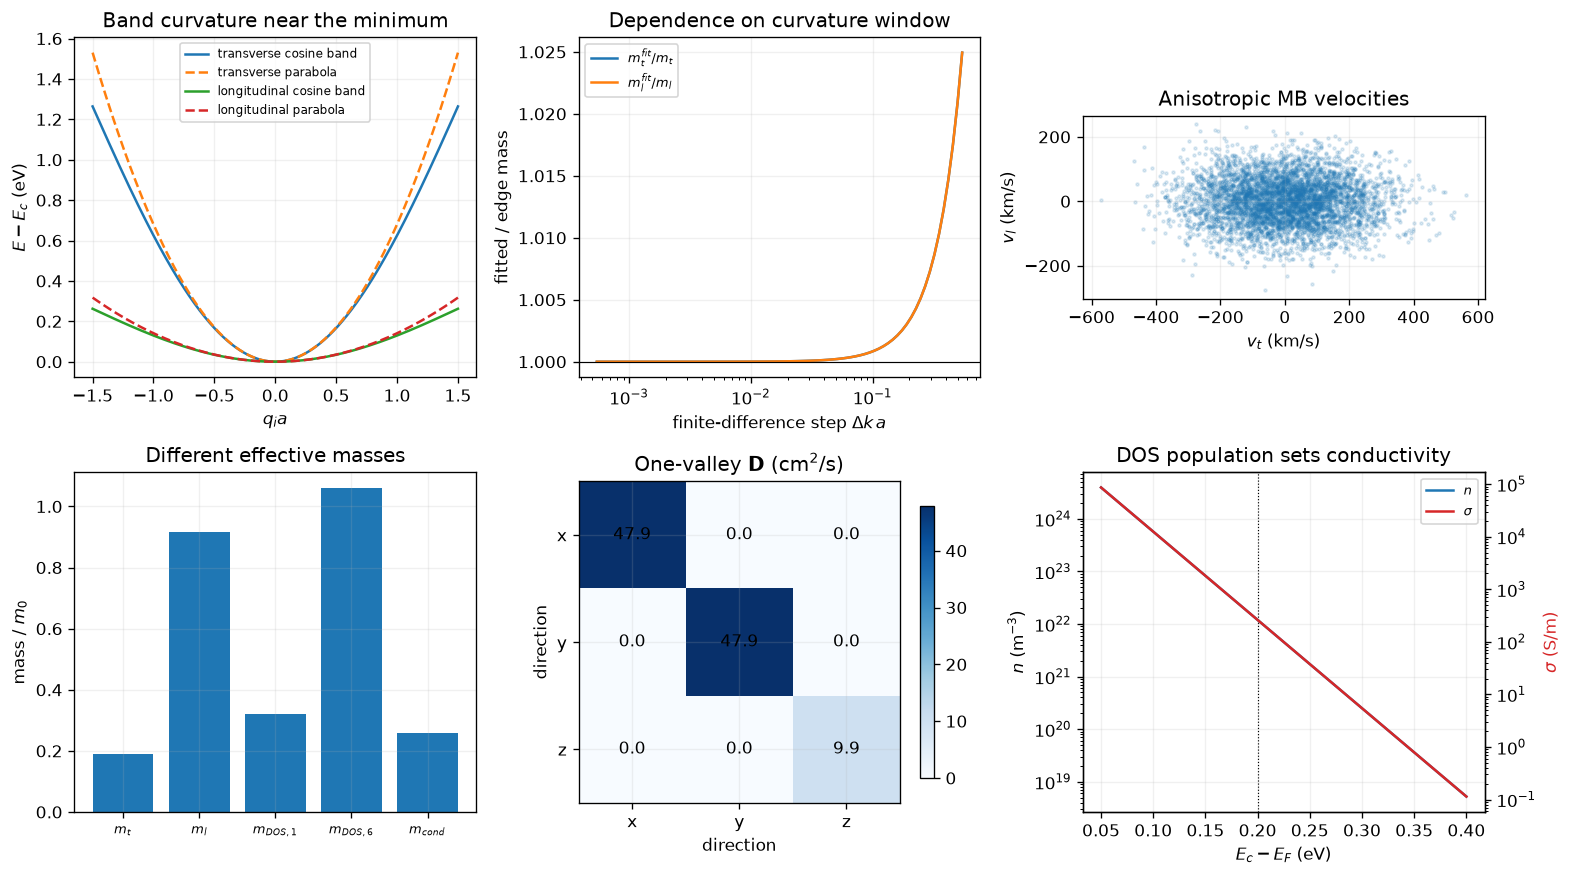

wrote lecture-notes/figures/08_brownian-motion-diffusion/lab-05-effective-mass-from-bands-to-transport.pdf


In [8]:
figure, axes = plt.subplots(2, 3, figsize=(13.2, 7.4))

axes[0, 0].plot(reduced_wavevector, transverse_band, label="transverse cosine band")
axes[0, 0].plot(reduced_wavevector, transverse_parabola, "--", label="transverse parabola")
axes[0, 0].plot(reduced_wavevector, longitudinal_band, label="longitudinal cosine band")
axes[0, 0].plot(reduced_wavevector, longitudinal_parabola, "--", label="longitudinal parabola")
axes[0, 0].set(title="Band curvature near the minimum", xlabel=r"$q_i a$", ylabel=r"$E-E_c$ (eV)")
axes[0, 0].legend(fontsize=7)

axes[0, 1].semilogx(curvature_steps * lattice_scale, window_mass[:, 0] / transverse_mass, label=r"$m_t^{fit}/m_t$")
axes[0, 1].semilogx(curvature_steps * lattice_scale, window_mass[:, 2] / longitudinal_mass, label=r"$m_l^{fit}/m_l$")
axes[0, 1].axhline(1.0, color="black", linewidth=0.7)
axes[0, 1].set(title="Dependence on curvature window", xlabel=r"finite-difference step $\Delta k\,a$", ylabel="fitted / edge mass")
axes[0, 1].legend(fontsize=8)

shown = slice(None, 5000)
axes[0, 2].scatter(velocity_samples[shown, 0] / 1e3, velocity_samples[shown, 2] / 1e3, s=3, alpha=0.15)
axes[0, 2].set_aspect("equal", adjustable="box")
axes[0, 2].set(title="Anisotropic MB velocities", xlabel=r"$v_t$ (km/s)", ylabel=r"$v_l$ (km/s)")

mass_names = [r"$m_t$", r"$m_l$", r"$m_{DOS,1}$", r"$m_{DOS,6}$", r"$m_{cond}$"]
mass_values = [transverse_mass, longitudinal_mass, one_valley_dos_mass, total_dos_mass, conductivity_mass]
axes[1, 0].bar(mass_names, np.array(mass_values) / electron_mass)
axes[1, 0].set(title="Different effective masses", ylabel=r"mass / $m_0$")
axes[1, 0].tick_params(axis="x", labelsize=8)

image = axes[1, 1].imshow(1.0e4 * one_valley_diffusivity, cmap="Blues")
axes[1, 1].set(title=r"One-valley $\mathbf{D}$ (cm$^2$/s)", xlabel="direction", ylabel="direction", xticks=range(3), yticks=range(3), xticklabels=["x", "y", "z"], yticklabels=["x", "y", "z"])
for i in range(3):
    for j in range(3):
        axes[1, 1].text(j, i, f"{1.0e4 * one_valley_diffusivity[i, j]:.1f}", ha="center", va="center")
figure.colorbar(image, ax=axes[1, 1], shrink=0.8)

axes[1, 2].semilogy(energy_offsets_ev, population_curve, label=r"$n$")
conductivity_axis = axes[1, 2].twinx()
conductivity_axis.semilogy(energy_offsets_ev, conductivity_curve, color="tab:red", label=r"$\sigma$")
axes[1, 2].axvline(fermi_level_below_edge_ev, color="black", linewidth=0.7, linestyle=":")
axes[1, 2].set(title="DOS population sets conductivity", xlabel=r"$E_c-E_F$ (eV)", ylabel=r"$n$ (m$^{-3}$)")
conductivity_axis.set_ylabel(r"$\sigma$ (S/m)", color="tab:red")
lines = axes[1, 2].lines[:1] + conductivity_axis.lines
axes[1, 2].legend(lines, [line.get_label() for line in lines], fontsize=8)

for axis in axes.flat:
    axis.grid(alpha=0.18)
figure.tight_layout()
output_path = OUTPUT / "lab-05-effective-mass-from-bands-to-transport.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": "DLSU SEMPHY01", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")

## 8. Interpretation and extensions

The complete modeling chain is

\[
E(\mathbf k)
\rightarrow \mathbf M^*
\rightarrow
\begin{cases}
 m_{\rm DOS}^* \rightarrow n,\\
 \mathbf M_{\rm cond}^* \rightarrow \mathbf D,\boldsymbol\mu,\boldsymbol\sigma,
\end{cases}
\rightarrow \text{particle and charge current}.
\]

Suggested investigations:

1. Increase the curvature-fitting window and explain why the fitted mass moves
   away from its band-edge value.
2. Populate only one valley. Is the conductivity still isotropic?
3. Change $E_c-E_F$. Separate the conductivity change caused by carrier
   population from the mobility, which is fixed here.
4. Replace the constant relaxation time by a direction- or energy-dependent
   model. Which scalar formulas cease to apply?
5. Near a valence-band maximum the electron curvature is negative. Reformulate
   the dynamics using positively charged holes with a positive hole mass.
6. The Maxwell–Boltzmann population formula fails in the degenerate regime;
   replace it with a Fermi–Dirac integral while retaining the band-curvature
   definition of effective mass where the parabolic approximation remains
   valid.